图像类型: <class 'numpy.ndarray'>, 图像形状(高,宽,通道): (164, 175, 3), 左上角像素: [0.9882353 0.9882353 0.6039216]


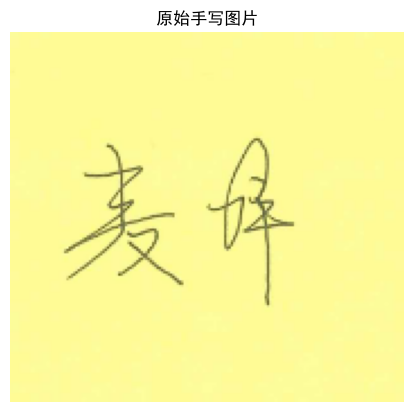

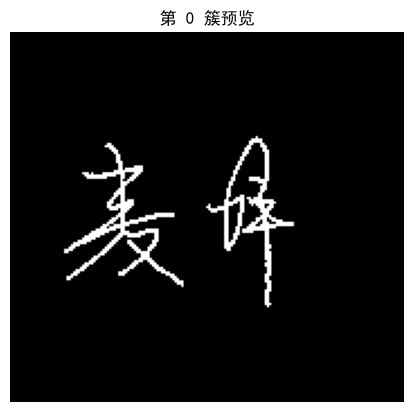

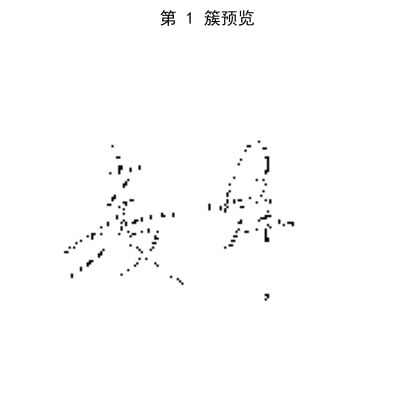

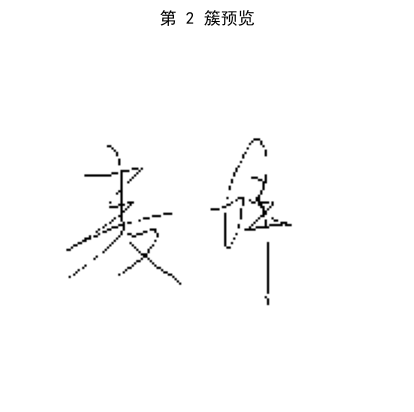

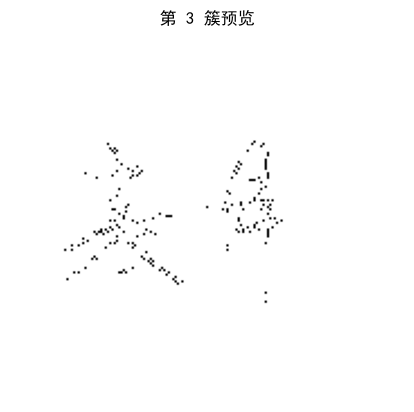

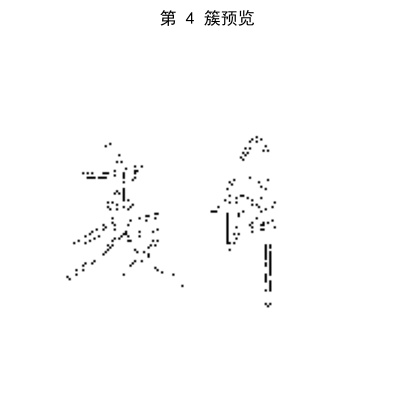

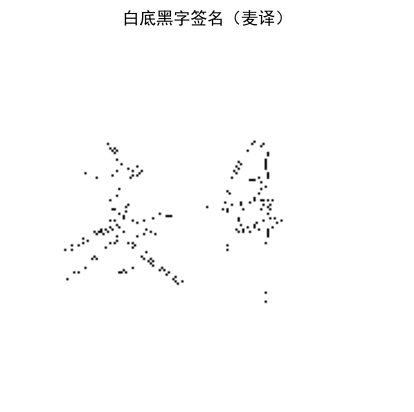

处理完成，图片已保存至：白底黑字签名（麦译）.jpg


In [1]:
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

img_path = r"mayi.png"
n_cluster = 5          # 聚类簇数量
target_tag = 3         # 需要提取的签名所在簇编号
save_path = "白底黑字签名（麦译）.jpg"

# 读取图像
img = mpimg.imread(img_path)
print(f"图像类型: {type(img)}, 图像形状(高,宽,通道): {img.shape}, 左上角像素: {img[0, 0]}")

# 展示原图
plt.figure()
plt.axis("off")
plt.imshow(img)
plt.title("原始手写图片")
plt.show()

h, w = img.shape[0], img.shape[1]
# 像素展平：(h,w,3) -> (h*w,3)，每行是一个像素RGB特征
img_flat = img.reshape(-1, 3)

# KMeans颜色聚类，固定随机种子保证结果复现
kmeans = KMeans(n_clusters=n_cluster, random_state=0, n_init="auto")
kmeans.fit(img_flat)
centers = kmeans.cluster_centers_.astype(np.int32)
label_map = kmeans.labels_.reshape(h, w)  # 二维标签图，和原图对齐

# 逐簇预览：每次只保留当前簇原色，其余置白色
for idx in range(n_cluster):
    # 向量化生成预览图，不再写两层for遍历像素
    preview_img = np.full((h, w, 3), fill_value=255, dtype=np.uint8)
    mask = label_map == idx
    preview_img[mask] = centers[idx]

    plt.figure()
    plt.axis("off")
    plt.imshow(preview_img)
    plt.title(f"第 {idx} 簇预览")
    plt.show()

# ===================== 提取目标簇，生成白底黑字签名 =====================
if target_tag not in np.unique(label_map):
    raise ValueError(f"错误：不存在编号为 {target_tag} 的簇！请核对上面预览的簇号")

# 向量化构建结果图：目标簇=黑色，其余=白色
result_img = np.full((h, w, 3), fill_value=255, dtype=np.uint8)
sign_mask = label_map == target_tag
result_img[sign_mask] = [0, 0, 0]

# 展示最终分割结果
plt.figure()
plt.axis("off")
plt.imshow(result_img)
plt.title("白底黑字签名（麦译）")
plt.show()

# 保存图片
plt.imsave(save_path, result_img)
print(f"处理完成，图片已保存至：{save_path}")
